In [150]:
# 錄製檔切分
import os
import json
from collections import deque
from collections.abc import Mapping
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pacsv

# 訓練模型
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import copy
from tqdm import tqdm

## 1. 把原始錄製檔，依據mode切分

In [153]:
COLS = ["Time (s)", "Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)", "Trigger", "Mode"]
CACHE_VERSION = 1
# 快取檔：欄位 -> (檔名, dtype)
CACHE_FILES = {"Time (s)": ("time.bin", np.float64), "Pressure (cmH2O)": ("pressure.bin", np.float64),
               "Flow (L/min)": ("flow.bin", np.float64), "Volume (mL)": ("volume.bin", np.float64),
               "Trigger": ("trigger.bin", np.int8), "Mode": ("mode.bin", np.int16)}

def load(csv_path, cache_dir=None):
    """
    讀入錄製檔，回傳輕量DataFrame（Time (s), Trigger, Mode），one row -> one sample point（100 Hz）
    """
    if cache_dir is None:
        cache_dir = os.path.splitext(csv_path)[0] + "_cache"
    src = os.stat(csv_path)
    meta_path = os.path.join(cache_dir, "meta.json")
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, encoding="utf-8") as f:
            meta = json.load(f)
        if (meta.get("version"), meta.get("size"), meta.get("mtime")) != (CACHE_VERSION, src.st_size, src.st_mtime):
            meta = None                                            # 錄製檔換過或快取格式不同 -> 重建
    if meta is None:
        meta = _build_cache(csv_path, cache_dir)
        meta.update(version=CACHE_VERSION, size=src.st_size, mtime=src.st_mtime)
        with open(meta_path, "w", encoding="utf-8") as f:          # 最後才寫 meta，中斷的快取不會被當成完整的
            json.dump(meta, f, ensure_ascii=False)

    read = lambda c: np.fromfile(os.path.join(cache_dir, CACHE_FILES[c][0]), CACHE_FILES[c][1])
    mode = pd.Categorical.from_codes(read("Mode"), categories=meta["modes"])
    wave = pd.DataFrame({"Time (s)": read("Time (s)"), "Trigger": read("Trigger"), "Mode": mode}, copy=False)
    wave.attrs["cache_dir"] = cache_dir                            # 給 cut_breaths 找波形用
    return wave


def _iter_batches(csv_path, block=32 << 20, workers=min(8, os.cpu_count() or 1)):
    """
    解壓後按「整行」切成 block，丟給多個執行緒平行解析，再照原順序一塊塊吐出
    （pyarrow 的串流讀取是單執行緒，太慢；同時在處理的 block 有上限，記憶體不會爆）
    """
    stream = pa.input_stream(csv_path, compression="gzip" if csv_path.endswith(".gz") else None)
    head = stream.read(1 << 16)                                    # 標頭在第一行
    nl = head.index(b"\n") + 1
    names = head[:nl].decode("utf-8-sig").rstrip("\r\n").split(",")
    types = {c: pa.float64() for c in COLS}
    types["Mode"] = pa.string()
    ropt = pacsv.ReadOptions(column_names=names, use_threads=False, block_size=block * 2)
    copt = pacsv.ConvertOptions(include_columns=COLS, column_types=types,
                                strings_can_be_null=True)          # 空字串當空值，同 pandas
    parse = lambda buf: pacsv.read_csv(pa.py_buffer(buf), read_options=ropt, convert_options=copt)

    pending, rest = deque(), head[nl:]
    with ThreadPoolExecutor(workers) as pool:
        while True:
            data = stream.read(block)
            buf = rest + data
            cut = len(buf) if not data else buf.rfind(b"\n") + 1   # 檔尾就整塊送出
            rest = buf[cut:]
            if cut:
                pending.append(pool.submit(parse, buf[:cut]))
            while pending and (len(pending) > workers + 2 or not data):
                yield from pending.popleft().result().to_batches()
            if not data:
                break


def _build_cache(csv_path, cache_dir):
    """平行解析錄製檔，邊讀邊寫成二進位快取，記憶體只用到幾個 block"""
    os.makedirs(cache_dir, exist_ok=True)
    meta_path = os.path.join(cache_dir, "meta.json")
    if os.path.exists(meta_path):
        os.remove(meta_path)
    cats = {}                                                      # 模式字串 -> category 編號
    files = {c: open(os.path.join(cache_dir, name), "wb") for c, (name, _) in CACHE_FILES.items()}
    try:
        for batch in _iter_batches(csv_path):
            batch = batch.filter(pc.is_valid(batch.column("Pressure (cmH2O)")))   # 同原版 dropna(subset=Pressure)
            for c in COLS[:4]:
                batch.column(c).to_numpy(zero_copy_only=False).astype(np.float64).tofile(files[c])
            trig = pc.fill_null(pc.equal(batch.column("Trigger"), 1.0), False)
            trig.to_numpy(zero_copy_only=False).astype(np.int8).tofile(files["Trigger"])
            # Mode：去掉前後空白後編成整數，-1 = 這列沒有 Mode
            enc = pc.utf8_trim_whitespace(batch.column("Mode")).dictionary_encode()
            lut = np.array([cats.setdefault(v, len(cats)) for v in enc.dictionary.to_pylist()] + [-1], np.int16)
            idx = pc.fill_null(enc.indices, -1).to_numpy(zero_copy_only=False)
            lut[idx].tofile(files["Mode"])
    finally:
        for f in files.values():
            f.close()
    return {"source": os.path.abspath(csv_path), "modes": list(cats)}


def mode_segments(wave, latency=1.5):
    """
    找出每段模式的時間範圍，回傳DataFrame：mode, start_time, end_time，範圍為 [start, end]
    - start_time：PSV沒有 trigger，取舊模式最後一次出現前最大延遲秒數內的trigger
    - end_time  ：取舊模式最後一次出現到新模式第一次出現之間最新的trigger
    """
    t = wave["Time (s)"].to_numpy()                                # 所有時間
    trig_t = t[wave["Trigger"].to_numpy() == 1]                    # 所有trigger的時間
    polls = wave.dropna(subset=["Mode"])                           # 只留下有Mode值的row
    pt, pm = polls["Time (s)"].to_numpy(), polls["Mode"].to_numpy()

    # 第一段從檔案開頭開始
    starts, modes = [t[0]], [pm[0]]

    # k = Mode 值和前一筆不同的位置（模式切換）
    for k in np.flatnonzero(pm[1:] != pm[:-1]) + 1:
        tA, tB = pt[k - 1], pt[k]                                  # tA:最後一次舊模式, tB:第一次新模式
        new = trig_t[(trig_t > tA) & (trig_t <= tB)]               # tA~tB之間的trigger
        old = trig_t[(trig_t <= tA) & (trig_t >= tA - latency)]    # tA為這個trigger的回應
        if len(new):
            b = new[-1]                                            # 最新的trigger(end_time)
        elif len(old):
            b = old[-1]                                            # 前一口trigger(start_time)
        else:
            b = tA                                                 # 兩邊都沒trigger，只能用tA
        starts.append(max(b, starts[-1]))                          # 不讓切換點早於前一段起點
        modes.append(pm[k])

    # 每段的結束 = 下一段的開始；最後一段到檔案結尾
    segs = pd.DataFrame({"mode": modes, "start_time": starts})
    segs["end_time"] = segs["start_time"].shift(-1).fillna(t[-1] + 0.01)
    # 拿掉長度為0的區間
    return segs[segs["end_time"] > segs["start_time"]].reset_index(drop=True)




SPONT_LABEL = "SPN-CPAP*"                    # SPN-CPAP但 Mode 未回報
MAX_GAP = 300                                # 秒，最大等待時間
def fill_spont_gaps(wave, segs, max_gap=MAX_GAP):
    """
    因為一號病人錄製檔前半段，在PSV期間沒有加入固定時間輪詢，所以才要這個function...
    若 PC區間內trigger間隔 > max_gap：插入SPONT區間 [前一個 trigger, 下一個 trigger)
    """
    t = wave["Time (s)"].to_numpy()
    trig_t = t[wave["Trigger"].to_numpy() == 1]
    rows = segs.to_dict("records")
    for i in np.flatnonzero(np.diff(trig_t) > max_gap):
        a, b = trig_t[i], trig_t[i + 1]
        for k, s in enumerate(rows):
            if s["start_time"] <= a and b <= s["end_time"] and not s["mode"].startswith("SPN-CPAP"):
                rows[k:k + 1] = [dict(s, end_time=a),
                                 dict(mode=SPONT_LABEL, start_time=a, end_time=b),
                                 dict(s, start_time=b)]
                break
    out = pd.DataFrame(rows)
    return out[out["end_time"] > out["start_time"]].reset_index(drop=True)


def find_breaths(wave, segs):
    """
    用 trigger 切呼吸，回傳DataFrame：breath_id, mode, boundary, start_time, end_time
    - 每兩個相鄰 trigger 之間是一口，不跨模式另切，所以模式切換處不會少一口
    - breath_id：起點是整個錄製檔第幾個 trigger（從1開始）
    - mode     ：起點落在哪一段模式區間（SPN-CPAP 段沒有 trigger，整段就是一口）
    - boundary ：模式切換前後各一口，可能混到前後模式，訓練時篩掉（編號照留，不影響其他口）
    - end_time ：是該口最後一個點的時間
    - 第一個 trigger 之前、最後一個 trigger 之後不是完整的一口，不列入
    """
    t = wave["Time (s)"].to_numpy()
    idx = np.flatnonzero(wave["Trigger"].to_numpy() == 1)         # 所有 trigger 的列
    starts, ends = t[idx[:-1]], t[idx[1:] - 1]                     # 相鄰兩個 trigger 為一口
    seg = np.maximum(np.searchsorted(segs["start_time"].to_numpy(), starts, side="right") - 1, 0)
    change = seg[1:] != seg[:-1]                                   # 這口和下一口在不同段
    boundary = np.zeros(len(seg), bool)
    boundary[:-1] |= change                                        # 切換前最後一口
    boundary[1:] |= change                                         # 切換後第一口
    return pd.DataFrame({"breath_id": np.arange(1, len(starts) + 1),
                         "mode": segs["mode"].to_numpy()[seg], "boundary": boundary,
                         "start_time": starts, "end_time": ends})


def cut_breaths(wave, breaths):
    """
    依breaths每口的起訖時間，從wave剪出波形

    回傳 BreathWaves（用法和 dict 一樣）：{breath_id: 該口波形 DataFrame}
      - 欄位：Time (s), Pressure, Flow, Volume
      - 列號從 0 重新編，Time (s) 保留原錄製檔時間
      - 波形留在 load() 的快取檔裡，取用某一口時才讀那一口，不會整包塞進記憶體
    """
    t = wave["Time (s)"].to_numpy()
    # 用二分搜尋一次找出所有口的起訖列號，不用每口掃整個檔
    # ±1e-9 是容差，避免浮點誤差漏掉起點或終點那一列
    s = np.searchsorted(t, breaths["start_time"].to_numpy() - 1e-9)                 # 起點列
    e = np.searchsorted(t, breaths["end_time"].to_numpy() + 1e-9, side="right")     # 終點列的下一列
    return BreathWaves(wave.attrs["cache_dir"], breaths["breath_id"].to_numpy(), s, np.maximum(e, s))


class BreathWaves(Mapping):
    """
    放在硬碟快取上的呼吸波形，用法和 dict 一樣：
      waves[breath_id]、list(waves)、len(waves)、for bid in waves、waves.items()
    """
    def __init__(self, cache_dir, ids, starts, ends):
        self.ids, self.starts, self.ends = ids, starts, ends
        self._pos = {int(b): k for k, b in enumerate(ids)}
        self._data = {c: np.memmap(os.path.join(cache_dir, name), dt, mode="r")
                      for c, (name, dt) in CACHE_FILES.items() if c in COLS[:4]}

    def __getitem__(self, bid):
        k = self._pos[bid]
        a, b = self.starts[k], self.ends[k]
        return pd.DataFrame({c: np.array(v[a:b]) for c, v in self._data.items()})

    def __iter__(self):
        return (int(b) for b in self.ids)

    def __len__(self):
        return len(self.ids)
# 執行完會有 waves：{breath_id: DataFrame(Time, Pressure, Flow, Volume)}，每口長度不一樣

In [155]:
path = r"D:\downloads"                           # 錄製檔存放資料夾位置
REC = "3.gz"      # 錄製檔名稱
OUTPUT_MODES = {"PC-AC"}                         # PC-AC、VC-AC、SPN-CPAP

In [157]:
# 根據mode切分每個mode的區間
wave = load(os.path.join(path, REC))
segs = fill_spont_gaps(wave, mode_segments(wave))
print(segs)
print("----------------------------------")

# 利用trigger切分呼吸
breaths = find_breaths(wave, segs)
print(breaths["mode"].value_counts())
print("----------------------------------")

# 利用OUTPUT_MODES篩出目標呼吸，並製作成waves，格式為<dict>
target_mode_breaths = breaths[breaths["mode"].isin(OUTPUT_MODES)]
waves = cut_breaths(wave, target_mode_breaths)
print(f"輸出 {len(waves)} 口：{sorted(OUTPUT_MODES)}")
print("----------------------------------")

       mode  start_time  end_time
0     VC-AC        0.00   7842.79
1     PC-AC     7842.79  20072.91
2  SPN-CPAP    20072.91  26628.48
3     VC-AC    26628.48  26649.96
4  SPN-CPAP    26649.96  38405.64
5     VC-AC    38405.64  38812.19
----------------------------------
mode
PC-AC       3107
VC-AC         31
SPN-CPAP       1
Name: count, dtype: int64
----------------------------------
輸出 3107 口：['PC-AC']
----------------------------------


## 2. 觀察資料集

In [160]:
t = waves._data["Time (s)"]

df_len = pd.DataFrame({
    "breath_id": waves.ids,
    "points":     waves.ends - waves.starts,
    "start_s":   t[waves.starts],
})
df_len["duration"] = df_len["points"] / 100

df_len = df_len.sort_values("duration").reset_index(drop=True)
df_len

,breath_id,points,start_s,duration
0,1951,1,15647.19,0.01
1,1154,6,13040.79,0.06
2,1466,163,14083.96,1.63
3,1733,166,14903.43,1.66
4,1348,167,13707.57,1.67
...,...,...,...,...
3102,262,504,9008.73,5.04
3103,2923,505,19271.84,5.05
3104,1005,506,12473.20,5.06
3105,2466,1179,17499.37,11.79


## 2. 整理成模型輸入： `(N Breath, 3, 256)`

In [163]:
L = 256                                                  # 每口呼吸重採樣後的點數
CH = ["Pressure (cmH2O)", "Flow (L/min)", "Volume (mL)"] # 3 個通道

def breath_to_array(df, L=L):
    old = np.linspace(0, 1, len(df))
    new = np.linspace(0, 1, L)
    return np.stack([np.interp(new, old, df[c].to_numpy()) for c in CH]).astype(np.float32)

ids, X, lens = [], [], []
dropped = []
for bid in waves:
    df = waves[bid]
    
    # 排除<0.2秒的不正常呼吸，
    if len(df) < 20:               
        dropped.append((bid, len(df)))
        continue
        
    ids.append(bid)
    X.append(breath_to_array(df))
    lens.append(len(df))
    
ids, X, lens = np.array(ids), np.stack(X), np.array(lens)

print("X shape =", X.shape)          # (N 口呼吸, 3 通道, 256 點)
print(f"丟掉 {len(dropped)} 口：")
for bid, n in dropped:
    print(f"  breath_id {bid}：{n} 點（{n/100:.2f} 秒）")

X shape = (3105, 3, 256)
丟掉 2 口：
  breath_id 1154：6 點（0.06 秒）
  breath_id 1951：1 點（0.01 秒）


## 3. 切 訓練集80%/驗證集20%

In [166]:
# seed=0, 隨機打散X排序
rng = np.random.default_rng(0)
perm = rng.permutation(len(X))

# 20% n 當作 val
n_val = int(len(X) * 0.2)

# 前20% val, 後80% train
va_idx, tr_idx = perm[:n_val], perm[n_val:]
print("train", X[tr_idx].shape)
print("val  ", X[va_idx].shape)

train (2484, 3, 256)
val   (621, 3, 256)


## 4. 標準化使用 `Standardization`
1. 因min-max容易受到極值的影響
2. Pressure, volume以0為基礎往上，但Flow是有症有負

In [169]:
# Standardization (z-score)： 
mean = X[tr_idx].mean(axis=(0, 2), keepdims=True)        # shape (1, 3, 1)：每個通道一個平均
std  = X[tr_idx].std(axis=(0, 2), keepdims=True) + 1e-6

# x' = (x - mean) / std
Xn = (X - mean) / std

# 轉成torch格式
X_tr = torch.from_numpy(Xn[tr_idx])
X_va = torch.from_numpy(Xn[va_idx])
print("train", X_tr.shape)
print("val  ", X_va.shape)

train torch.Size([2484, 3, 256])
val   torch.Size([621, 3, 256])


## 5. 建模型

In [172]:
# resampling後，共3*256=768，latent壓縮成16，這樣是48倍壓縮
LATENT = 16 

class ConvAE(nn.Module):
    def __init__(self, in_ch=3, L=L, latent=LATENT):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(in_ch, 16, 7, stride=2, padding=3), nn.ReLU(),   # (N,  3, 256)  -> (N, 16, 128)
            nn.Conv1d(16, 32, 7, stride=2, padding=3), nn.ReLU(),      # (N, 16, 128)  -> (N, 32,  64)
            nn.Conv1d(32, 64, 7, stride=2, padding=3), nn.ReLU(),      # (N, 32,  64)  -> (N, 64,  32)
            nn.Flatten(),                                              # 64*32 = 2048
            nn.Linear(64 * (L // 8), latent),                          # 64*(32)-> latent
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 64 * (L // 8)), nn.ReLU(),                    # 64*(32)-> latent
            nn.Unflatten(1, (64, L // 8)),                                  # 64*32 = 2048
            nn.ConvTranspose1d(64, 32, 4, stride=2, padding=1), nn.ReLU(),  # (N, 64,  32)  -> (N, 32,  64)
            nn.ConvTranspose1d(32, 16, 4, stride=2, padding=1), nn.ReLU(),  # (N, 64,  32)  -> (N, 16, 128)
            nn.ConvTranspose1d(16, in_ch, 4, stride=2, padding=1),          # (N, 16, 128)  -> (N,  3, 256)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

model = ConvAE()
print(model(X_tr[:2]).shape)   # 檢查：應該是 torch.Size([2, 3, 256])，跟輸入一樣

torch.Size([2, 3, 256])


## 6. 訓練

epoch   0  train 0.65559  val 0.18814  * best


epoch   1  train 0.11100  val 0.08714  * best


epoch   2  train 0.07345  val 0.06836  * best


epoch   3  train 0.05909  val 0.05583  * best


epoch   4  train 0.04895  val 0.04525  * best


epoch   5  train 0.04017  val 0.03591  * best


... (100 outputs left out)

epoch 106  train 0.00294  val 0.00433  (no improvement 7/10)


epoch 107  train 0.00304  val 0.00408  (no improvement 8/10)


epoch 108  train 0.00281  val 0.00415  (no improvement 9/10)


epoch 109  train 0.00289  val 0.00438  (no improvement 10/10)

Early stop at epoch 109
Using epoch 99 model, best val = 0.00406


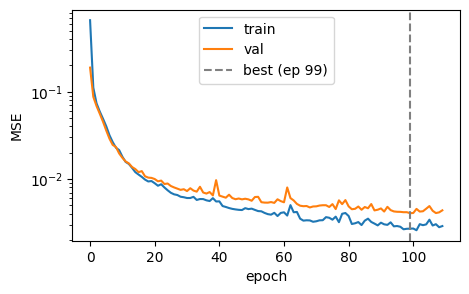

In [175]:
torch.manual_seed(0)
model = ConvAE()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
loader = torch.utils.data.DataLoader(X_tr, batch_size=64, shuffle=True)

MAX_EPOCHS = 300
PATIENCE   = 10
MIN_DELTA  = 1e-5

hist = {"train": [], "val": []}
best_val, best_ep, best_state, wait = float("inf"), -1, None, 0

# 開始training
for ep in range(MAX_EPOCHS):
    model.train()
    tot, seen = 0, 0
    bar = tqdm(loader, desc=f"epoch {ep:3d}", leave=False)      # 這個epoch進度條
    for x in bar:
        loss = loss_fn(model(x), x)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(x); seen += len(x)
        bar.set_postfix(loss=f"{tot / seen:.5f}")              # 即時顯示目前平均loss
    tr = tot / len(X_tr)

    model.eval()
    with torch.no_grad():
        va = loss_fn(model(X_va), X_va).item()
    hist["train"].append(tr); hist["val"].append(va)

    if va < best_val - MIN_DELTA:
        best_val, best_ep, wait = va, ep, 0
        best_state = copy.deepcopy(model.state_dict())
        mark = "  * best"
    else:
        wait += 1
        mark = f"  (no improvement {wait}/{PATIENCE})"
    print(f"epoch {ep:3d}  train {tr:.5f}  val {va:.5f}{mark}")

    if wait >= PATIENCE:
        print(f"\nEarly stop at epoch {ep}")
        break

model.load_state_dict(best_state)
print(f"Using epoch {best_ep} model, best val = {best_val:.5f}")

plt.figure(figsize=(5, 3))
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.axvline(best_ep, color="gray", ls="--", label=f"best (ep {best_ep})")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

## 6. 看還原效果

In [177]:
def reconstruct(bid):
    """給 breath_id，回傳 (原始, 還原)，都已換回原本單位，shape (3, L)"""
    k = np.where(ids == bid)[0][0]
    model.eval()
    with torch.no_grad():
        out = model(torch.from_numpy(Xn[k:k+1])).numpy()
    return X[k], (out * std + mean)[0]

def plot_recon(bid):
    x, xh = reconstruct(bid)
    fig, ax = plt.subplots(3, 1, figsize=(7, 5), sharex=True)
    for i, name in enumerate(CH):
        ax[i].plot(x[i], label="original"); ax[i].plot(xh[i], "--", label="reconstructed")
        ax[i].set_ylabel(name)
    ax[0].set_title(f"Breath {bid}   score={scores[ids == bid][0]:.3f}"); ax[0].legend()
    ax[-1].set_xlabel(f"resampled point (0..{L-1})")
    plt.tight_layout(); plt.show()

## 7. 還原誤差 = 異常分數

每口呼吸算一個 MSE。大部分呼吸是正常的，模型學會的是「正常長怎樣」，
所以分數特別高的那些就是值得去看的候選 PVA。

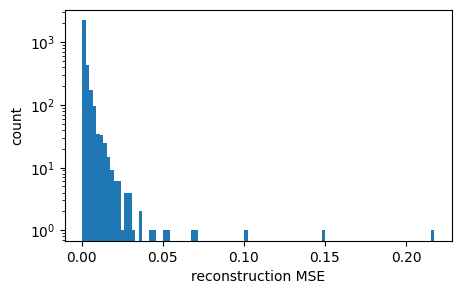

分數最高的 10 口： [2466, 1466, 1387, 1549, 1640, 1488, 2683, 1790, 2042, 2063]
分數最低的 5 口： [369, 318, 358, 363, 241]


In [180]:
model.eval()
with torch.no_grad():
    Xt = torch.from_numpy(Xn)
    scores = ((model(Xt) - Xt) ** 2).mean(dim=(1, 2)).numpy()   # 每口呼吸一個分數
    Z = model.encoder(Xt).numpy()                                 # 每口呼吸的潛在向量 (N, 16)

plt.figure(figsize=(5, 3))
plt.hist(scores, bins=100); plt.yscale("log")
plt.xlabel("reconstruction MSE"); plt.ylabel("count"); plt.show()

order = np.argsort(scores)[::-1]
print("分數最高的 10 口：", ids[order[:10]].tolist())
print("分數最低的 5 口：", ids[order[-5:]].tolist())

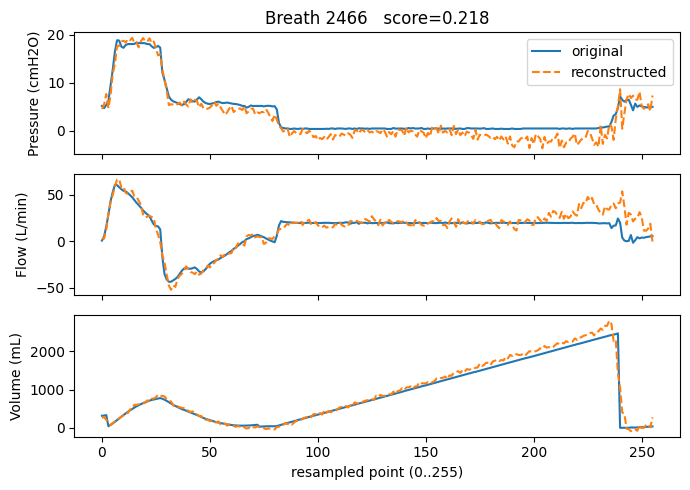

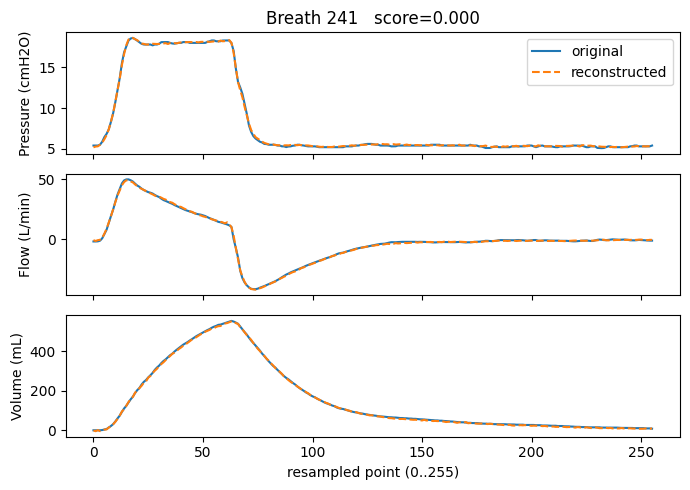

In [182]:
plot_recon(ids[order[0]])     # 最異常的一口
plot_recon(ids[order[-1]])    # 最正常的一口

## 9. 觀察latent的z分布

In [203]:
import os, warnings
warnings.filterwarnings("ignore", message="IProgress not found")       # tqdm 找不到 ipywidgets（無害）
from joblib.externals.loky.backend import context as _loky
_loky.physical_cores_cache = os.cpu_count()                            # sklearn 找不到 CPU 核心數（無害）

import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

from sklearn.preprocessing import StandardScaler

Zs = StandardScaler().fit_transform(Z)          # 三種方法都用標準化後的 Z
vmax = np.percentile(scores, 99)                # 色條上限，避免少數極端值讓其他點都變同一色

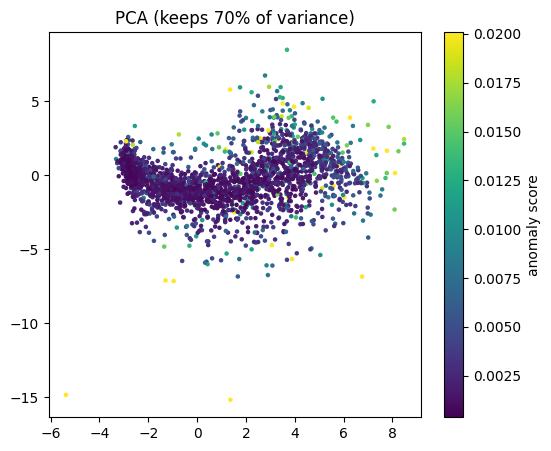

In [193]:
from sklearn.decomposition import PCA

pca = PCA(2).fit(Zs)
P = pca.transform(Zs)

plt.figure(figsize=(6, 5))
plt.scatter(P[:, 0], P[:, 1], c=scores, cmap="viridis", s=5, vmax=vmax)
plt.colorbar(label="anomaly score")
plt.title(f"PCA (keeps {pca.explained_variance_ratio_.sum():.0%} of variance)")
plt.show()

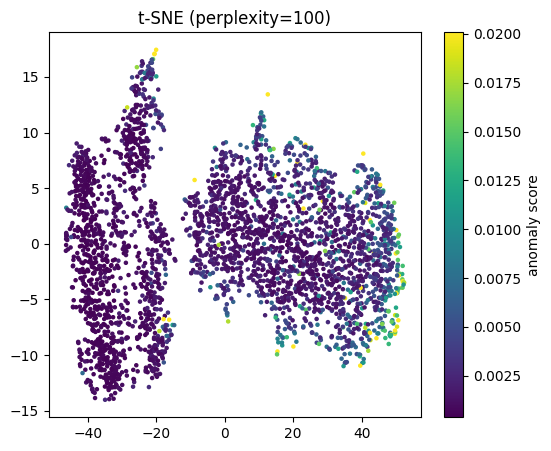

In [219]:
from sklearn.manifold import TSNE
perplexity=100

T = TSNE(2, perplexity=perplexity, init="pca", random_state=0).fit_transform(Zs)

plt.figure(figsize=(6, 5))
plt.scatter(T[:, 0], T[:, 1], c=scores, cmap="viridis", s=5, vmax=vmax)
plt.colorbar(label="anomaly score")
plt.title(f"t-SNE (perplexity={perplexity})")
plt.show()

C:\Users\wahas\AppData\Roaming\Python\Python312\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


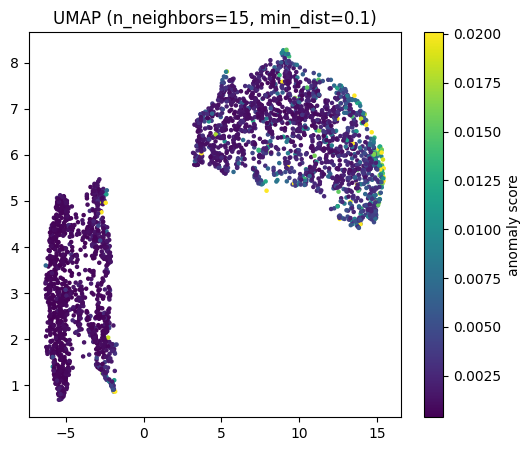

In [216]:
import umap

U = umap.UMAP(n_components=2, n_neighbors=50, min_dist=0.1, random_state=0).fit_transform(Zs)

plt.figure(figsize=(6, 5))
plt.scatter(U[:, 0], U[:, 1], c=scores, cmap="viridis", s=5, vmax=vmax)
plt.colorbar(label="anomaly score")
plt.title("UMAP (n_neighbors=15, min_dist=0.1)")
plt.show()